In [2]:

import sys
import csv
import json
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)

# Find project root
CWD = Path.cwd().resolve()

if (CWD / "src" / "catalog_classifier.py").exists():
    ROOT = CWD
elif (CWD.parent / "src" / "catalog_classifier.py").exists():
    ROOT = CWD.parent
else:
    raise FileNotFoundError(
        "Open this notebook from the RetailMind-AI project."
    )

sys.path.insert(0, str(ROOT))

from src.catalog_classifier import build_catalog_cnn

# Find dataset already downloaded during Day 6
CACHE_DIR = Path.home() / ".keras" / "retailmind_day6"

candidates = [
    p.parent
    for p in CACHE_DIR.rglob("styles.csv")
    if (p.parent / "images").is_dir()
]

if not candidates:
    raise FileNotFoundError(
        "Dataset missing from the Day 6 cache."
    )

# Prefer the nested Myntra dataset folder
DATA_DIR = max(candidates, key=lambda p: len(p.parts))

STYLES_CSV = DATA_DIR / "styles.csv"
IMAGES_DIR = DATA_DIR / "images"

MODELS_DIR = ROOT / "models"
DOCS_DIR = ROOT / "docs"
SYNTH_DIR = ROOT / "data" / "synthetic" / "day11"

for folder in [MODELS_DIR, DOCS_DIR, SYNTH_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Day 6 classification configuration
LABEL_COLUMN = "subCategory"
CNN_IMAGE_SIZE = 128

# VAE configuration
VAE_IMAGE_SIZE = 64
LATENT_DIM = 32
VAE_EPOCHS = 20

# Experiment configuration
BATCH_SIZE = 32
CNN_EPOCHS = 5
MIN_CLASS_IMAGES = 100

# Limit images per class for a manageable experiment.
# Change to None later to use all available training images.
MAX_TRAIN_PER_CLASS = 300
MAX_EVAL_PER_CLASS = 80

print("Project root:", ROOT)
print("Dataset:", DATA_DIR)
print("CSV found:", STYLES_CSV.exists())
print("Images found:", IMAGES_DIR.exists())
print("TensorFlow:", tf.__version__)


Project root: C:\Users\Abhishek\Desktop\RetailMind-AI
Dataset: C:\Users\Abhishek\.keras\retailmind_day6\fashion-product-images-small_extracted\myntradataset
CSV found: True
Images found: True
TensorFlow: 2.21.0


In [3]:

records = []

with open(STYLES_CSV, encoding="utf-8", errors="replace") as f:
    reader = csv.DictReader(f)

    for row in reader:
        product_id = (row.get("id") or "").strip()
        label = (row.get(LABEL_COLUMN) or "").strip()

        if not product_id or not label:
            continue

        image_path = IMAGES_DIR / f"{product_id}.jpg"

        if image_path.is_file():
            records.append((str(image_path), label))

original_counts = Counter(label for _, label in records)

class_names = sorted([
    label for label, count in original_counts.items()
    if count >= MIN_CLASS_IMAGES
])

records = [
    (path, label)
    for path, label in records
    if label in class_names
]

if len(class_names) < 2:
    raise ValueError("At least two categories are required.")

label_to_id = {
    label: i for i, label in enumerate(class_names)
}

grouped = defaultdict(list)

for path, label in records:
    grouped[label].append(path)

rng = np.random.default_rng(SEED)

train_items = []
val_items = []
test_items = []

for label in class_names:
    paths = sorted(grouped[label])
    rng.shuffle(paths)

    n = len(paths)
    n_holdout = max(1, round(n * 0.10))

    test_paths = paths[:n_holdout]
    val_paths = paths[n_holdout:2 * n_holdout]
    train_paths = paths[2 * n_holdout:]

    if MAX_TRAIN_PER_CLASS is not None:
        train_paths = train_paths[:MAX_TRAIN_PER_CLASS]

    if MAX_EVAL_PER_CLASS is not None:
        val_paths = val_paths[:MAX_EVAL_PER_CLASS]
        test_paths = test_paths[:MAX_EVAL_PER_CLASS]

    train_items.extend((p, label) for p in train_paths)
    val_items.extend((p, label) for p in val_paths)
    test_items.extend((p, label) for p in test_paths)

train_counts = Counter(label for _, label in train_items)

print("Number of categories:", len(class_names))
print("Training images:", len(train_items))
print("Validation images:", len(val_items))
print("Testing images:", len(test_items))

print("\nCategory counts:")
for label in sorted(class_names, key=lambda x: original_counts[x]):
    print(
        f"{label:24s} "
        f"Original: {original_counts[label]:5d} | "
        f"Train: {train_counts[label]:4d}"
    )


Number of categories: 27
Training images: 6812
Validation images: 1478
Testing images: 1478

Category counts:
Free Gifts               Original:   104 | Train:   84
Apparel Set              Original:   106 | Train:   84
Cufflinks                Original:   108 | Train:   86
Scarves                  Original:   118 | Train:   94
Accessories              Original:   143 | Train:  115
Ties                     Original:   258 | Train:  206
Headwear                 Original:   293 | Train:  235
Makeup                   Original:   307 | Train:  245
Nails                    Original:   329 | Train:  263
Saree                    Original:   427 | Train:  300
Loungewear and Nightwear Original:   470 | Train:  300
Dress                    Original:   478 | Train:  300
Lips                     Original:   527 | Train:  300
Socks                    Original:   698 | Train:  300
Belts                    Original:   811 | Train:  300
Flip Flops               Original:   915 | Train:  300
Wallets   

In [4]:

def load_image(path, image_size):
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [image_size, image_size]
    )

    return tf.cast(image, tf.float32) / 255.0


def make_dataset(items, training=False):
    paths = [path for path, label in items]

    labels = np.array([
        label_to_id[label]
        for path, label in items
    ], dtype=np.int32)

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            len(items),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        lambda path, label: (
            load_image(path, CNN_IMAGE_SIZE),
            label
        ),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)

    if training:
        augmentation = keras.Sequential([
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.08),
            layers.RandomZoom(0.10)
        ])

        ds = ds.map(
            lambda x, y: (
                augmentation(x, training=True), y
            ),
            num_parallel_calls=tf.data.AUTOTUNE
        )

    return ds.prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(train_items, training=True)
val_ds = make_dataset(val_items)
test_ds = make_dataset(test_items)

print("TensorFlow datasets ready.")


TensorFlow datasets ready.


In [5]:

keras.utils.set_random_seed(SEED)

baseline_model = build_catalog_cnn(
    input_shape=(CNN_IMAGE_SIZE, CNN_IMAGE_SIZE, 3),
    class_count=len(class_names)
)

baseline_model.summary()

baseline_history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=CNN_EPOCHS,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ],
    verbose=1
)

baseline_model.save(
    MODELS_DIR / "day11_baseline_cnn.keras"
)

print("Baseline model trained and saved.")


Model: "retailmind_catalog_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 27)             │         3,483 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 113,243 (442.36 KB)

 Trainable params: 113,243 (442.36 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5


c:\Users\Abhishek\Desktop\RetailMind-AI\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


213/213 ━━━━━━━━━━━━━━━━━━━━ 133s 603ms/step - accuracy: 0.0694 - loss: 3.1816 - val_accuracy: 0.1414 - val_loss: 2.9204
Epoch 2/5
213/213 ━━━━━━━━━━━━━━━━━━━━ 90s 421ms/step - accuracy: 0.1248 - loss: 2.9274 - val_accuracy: 0.2070 - val_loss: 2.7038
Epoch 3/5
213/213 ━━━━━━━━━━━━━━━━━━━━ 85s 399ms/step - accuracy: 0.1654 - loss: 2.7679 - val_accuracy: 0.1867 - val_loss: 2.7628
Epoch 4/5
213/213 ━━━━━━━━━━━━━━━━━━━━ 84s 394ms/step - accuracy: 0.1952 - loss: 2.6463 - val_accuracy: 0.2997 - val_loss: 2.4190
Epoch 5/5
213/213 ━━━━━━━━━━━━━━━━━━━━ 88s 413ms/step - accuracy: 0.2466 - loss: 2.4258 - val_accuracy: 0.3491 - val_loss: 2.1966
Baseline model trained and saved.


In [15]:

# Manually select a visually consistent minority category
target_class = "Ties"

target_paths = [
    path for path, label in train_items
    if label == target_class
]

# Train the VAE longer than the previous attempt
VAE_EPOCHS = 40

print("Selected category:", target_class)
print("Training images:", len(target_paths))
print("VAE epochs:", VAE_EPOCHS)


Selected category: Ties
Training images: 206
VAE epochs: 40


Confusion matrix source: Day 11 baseline validation

Minority category candidates:
Free Gifts | Images: 104 | Recall: 0.0
Apparel Set | Images: 106 | Recall: 0.0
Cufflinks | Images: 108 | Recall: 0.0
Scarves | Images: 118 | Recall: 0.0
Accessories | Images: 143 | Recall: 0.0
Ties | Images: 258 | Recall: 0.154
Headwear | Images: 293 | Recall: 0.379
Makeup | Images: 307 | Recall: 0.0
Nails | Images: 329 | Recall: 0.0

Selected category for VAE: Free Gifts
Training images available: 84


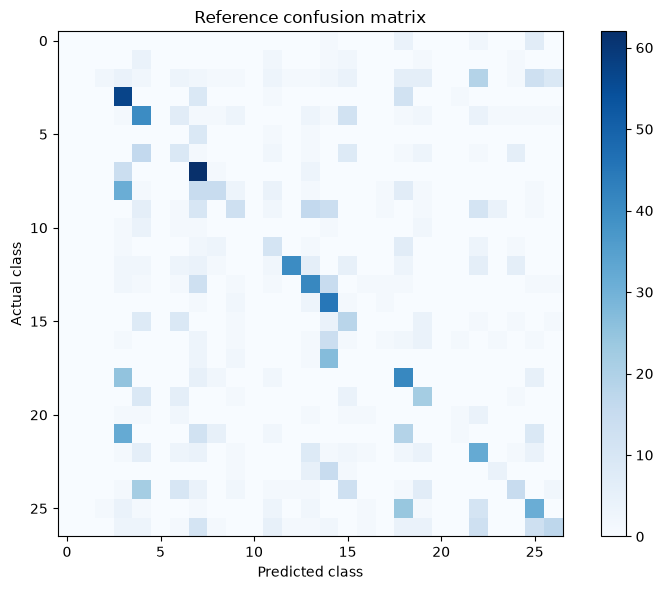

In [16]:

# Predict validation categories
val_probs = baseline_model.predict(
    val_ds, verbose=0
)

val_pred = np.argmax(val_probs, axis=1)

val_true = np.array([
    label_to_id[label]
    for path, label in val_items
])

baseline_val_cm = tf.math.confusion_matrix(
    val_true,
    val_pred,
    num_classes=len(class_names)
).numpy()

reference_cm = baseline_val_cm
reference_source = "Day 11 baseline validation"

# Try to reuse the earlier Phase-2 confusion matrix
previous_cm_path = MODELS_DIR / "day7_confusion_matrix.npy"
previous_names_path = MODELS_DIR / "day7_class_names.json"

if previous_cm_path.exists() and previous_names_path.exists():
    old_cm = np.load(previous_cm_path)
    old_names = json.loads(
        previous_names_path.read_text(encoding="utf-8")
    )

    if (
        len(old_names) == len(class_names)
        and set(old_names) == set(class_names)
        and old_cm.shape == (len(old_names), len(old_names))
    ):
        order = [
            old_names.index(name)
            for name in class_names
        ]

        reference_cm = old_cm[np.ix_(order, order)]
        reference_source = "Day 7 Phase-2 confusion matrix"

reference_support = reference_cm.sum(axis=1)

reference_recall = (
    np.diag(reference_cm)
    / np.maximum(reference_support, 1)
)

# Smallest third of categories by original dataset size
ordered_classes = sorted(
    class_names,
    key=lambda name: original_counts[name]
)

minority_count = max(1, (len(class_names) + 2) // 3)

minority_candidates = [
    name for name in ordered_classes[:minority_count]
    if train_counts[name] >= 64
]

if not minority_candidates:
    raise ValueError(
        "No minority category has enough VAE training images."
    )

# Prefer a minority category with low previous recall
target_class = min(
    minority_candidates,
    key=lambda name: (
        reference_recall[label_to_id[name]],
        original_counts[name]
    )
)

print("Confusion matrix source:", reference_source)
print("\nMinority category candidates:")

for name in minority_candidates:
    idx = label_to_id[name]

    print(
        name,
        "| Images:", original_counts[name],
        "| Recall:", round(float(reference_recall[idx]), 3)
    )

print("\nSelected category for VAE:", target_class)
print("Training images available:", train_counts[target_class])

plt.figure(figsize=(8, 6))
plt.imshow(reference_cm, cmap="Blues")
plt.colorbar()
plt.title("Reference confusion matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.tight_layout()
plt.show()


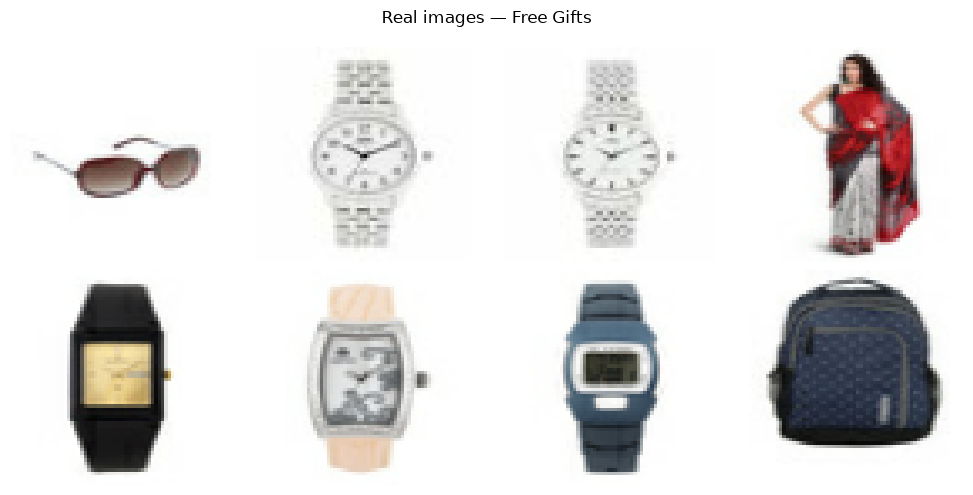

In [7]:

target_paths = [
    path for path, label in train_items
    if label == target_class
]

vae_ds = tf.data.Dataset.from_tensor_slices(
    target_paths
)

vae_ds = vae_ds.shuffle(
    len(target_paths),
    seed=SEED
)

vae_ds = vae_ds.map(
    lambda path: load_image(path, VAE_IMAGE_SIZE),
    num_parallel_calls=tf.data.AUTOTUNE
)

vae_ds = vae_ds.map(
    tf.image.random_flip_left_right,
    num_parallel_calls=tf.data.AUTOTUNE
)

vae_ds = vae_ds.batch(
    BATCH_SIZE
).prefetch(tf.data.AUTOTUNE)

# Display real category images
fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for ax, path in zip(axes.flat, target_paths[:8]):
    image = load_image(
        path, VAE_IMAGE_SIZE
    ).numpy()

    ax.imshow(image)
    ax.axis("off")

plt.suptitle(f"Real images — {target_class}")
plt.tight_layout()
plt.show()


In [17]:

class Sampling(layers.Layer):
    def call(self, inputs):
        mean, log_var = inputs

        epsilon = tf.random.normal(
            shape=tf.shape(mean)
        )

        return mean + tf.exp(0.5 * log_var) * epsilon


# Encoder
encoder_inputs = keras.Input(
    shape=(VAE_IMAGE_SIZE, VAE_IMAGE_SIZE, 3)
)

x = layers.Conv2D(
    32, 3, strides=2,
    padding="same",
    activation="relu"
)(encoder_inputs)

x = layers.Conv2D(
    64, 3, strides=2,
    padding="same",
    activation="relu"
)(x)

x = layers.Conv2D(
    128, 3, strides=2,
    padding="same",
    activation="relu"
)(x)

x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)

z_mean = layers.Dense(LATENT_DIM)(x)
z_log_var = layers.Dense(LATENT_DIM)(x)

z = Sampling()([z_mean, z_log_var])

encoder = keras.Model(
    encoder_inputs,
    [z_mean, z_log_var, z],
    name="day11_encoder"
)


# Decoder
decoder_inputs = keras.Input(
    shape=(LATENT_DIM,)
)

x = layers.Dense(
    8 * 8 * 128,
    activation="relu"
)(decoder_inputs)

x = layers.Reshape((8, 8, 128))(x)

x = layers.Conv2DTranspose(
    128, 3, strides=2,
    padding="same",
    activation="relu"
)(x)

x = layers.Conv2DTranspose(
    64, 3, strides=2,
    padding="same",
    activation="relu"
)(x)

x = layers.Conv2DTranspose(
    32, 3, strides=2,
    padding="same",
    activation="relu"
)(x)

decoder_outputs = layers.Conv2D(
    3, 3,
    padding="same",
    activation="sigmoid"
)(x)

decoder = keras.Model(
    decoder_inputs,
    decoder_outputs,
    name="day11_decoder"
)


# VAE model with custom training step
class VAE(keras.Model):
    def __init__(self, encoder, decoder):
        super().__init__()

        self.encoder = encoder
        self.decoder = decoder

        self.total_loss_tracker = keras.metrics.Mean(
            name="total_loss"
        )

        self.reconstruction_tracker = keras.metrics.Mean(
            name="reconstruction_loss"
        )

        self.kl_tracker = keras.metrics.Mean(
            name="kl_loss"
        )

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_tracker,
            self.kl_tracker
        ]

    def train_step(self, data):
        if isinstance(data, (tuple, list)):
            data = data[0]

        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(
                data, training=True
            )

            reconstructed = self.decoder(
                z, training=True
            )

            reconstruction_loss = tf.reduce_mean(
                tf.reduce_mean(
                    tf.square(data - reconstructed),
                    axis=[1, 2, 3]
                )
            )

            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + z_log_var
                    - tf.square(z_mean)
                    - tf.exp(z_log_var),
                    axis=1
                )
            )

            total_loss = (
                reconstruction_loss + 0.001 * kl_loss
            )

        gradients = tape.gradient(
            total_loss,
            self.trainable_weights
        )

        self.optimizer.apply_gradients(
            zip(gradients, self.trainable_weights)
        )

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_tracker.update_state(
            reconstruction_loss
        )
        self.kl_tracker.update_state(kl_loss)

        return {
            metric.name: metric.result()
            for metric in self.metrics
        }


vae = VAE(encoder, decoder)

vae.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    )
)

encoder.summary()
decoder.summary()


Model: "day11_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │        896 │ input_layer_4[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │     18,496 │ conv2d_7[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 8, 8, 128) │     73,856 │ conv2d_8[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 8192)      │          0 │ conv2d_9[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 128)       │  1,048,704 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 32)        │      4,128 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 32)        │      4,128 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling_1          │ (None, 32)        │          0 │ dense_7[0][0],    │
│ (Sampling)          │                   │            │ dense_8[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,150,208 (4.39 MB)

 Trainable params: 1,150,208 (4.39 MB)

 Non-trainable params: 0 (0.00 B)

Model: "day11_decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 8192)           │       270,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 16, 16, 128)    │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 32, 32, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 64, 64, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 64, 64, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 511,043 (1.95 MB)

 Trainable params: 511,043 (1.95 MB)

 Non-trainable params: 0 (0.00 B)

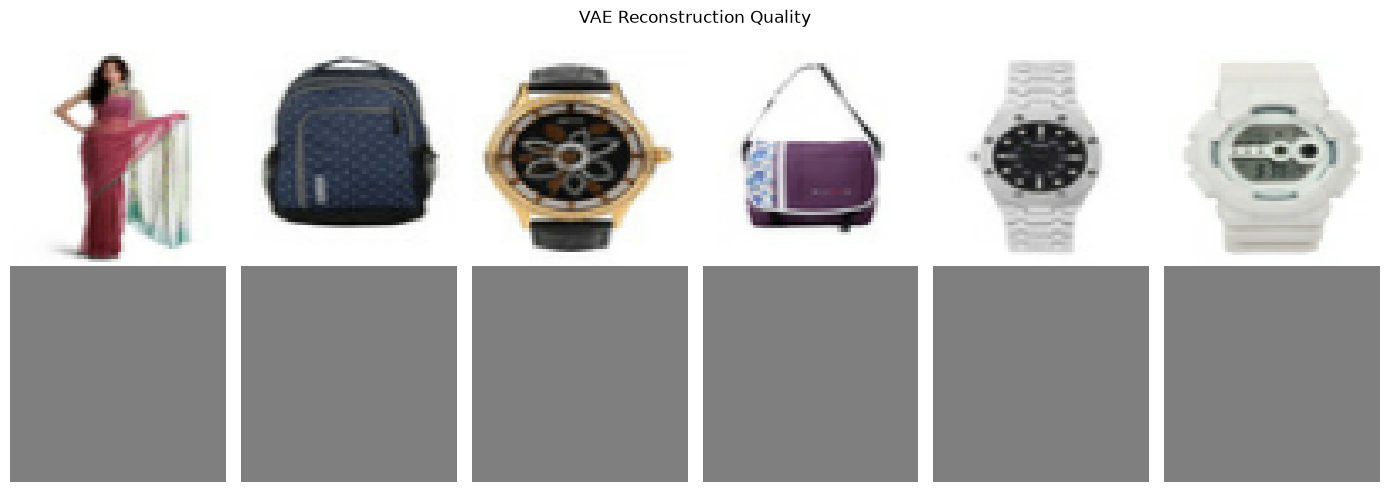

Original pixel std: 0.27805468440055847
Reconstruction pixel std: 0.00014058045053388923
Generated pixel std: 0.0011440739035606384
Original pixel std: 0.27805468440055847
Reconstruction pixel std: 0.00014058045053388923
Generated pixel std: 0.0011440739035606384


In [18]:

# Compare real images with VAE reconstructions

real_batch = next(iter(vae_ds))

z_mean, z_log_var, z = encoder(
    real_batch, training=False
)

reconstructed = decoder(
    z_mean, training=False
).numpy()

fig, axes = plt.subplots(2, 6, figsize=(14, 5))

for i in range(6):
    axes[0, i].imshow(real_batch[i].numpy())
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed[i])
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("Reconstructed", fontsize=12)

plt.suptitle("VAE Reconstruction Quality")
plt.tight_layout()
plt.show()

print("Original pixel std:", float(tf.math.reduce_std(real_batch)))
print("Reconstruction pixel std:", float(np.std(reconstructed)))
print("Generated pixel std:", float(np.std(generated_images)))
print("Original pixel std:", float(tf.math.reduce_std(real_batch)))
print("Reconstruction pixel std:", float(np.std(reconstructed)))
print("Generated pixel std:", float(np.std(generated_images)))

In [19]:

from collections import Counter

print("Selected minority category:", target_class)

print("\nNumber of VAE training images:", len(target_paths))

path_to_label = dict(train_items)

labels_in_vae = Counter(
    path_to_label.get(path, "UNKNOWN")
    for path in target_paths
)

print("\nCategories in VAE training paths:")
print(labels_in_vae)

print("\nVAE dataset structure:")
print(vae_ds.element_spec)

print("\nCheck trained model file:")
print(
    (MODELS_DIR / "day11_vae_decoder.keras").exists()
)


Selected minority category: Free Gifts

Number of VAE training images: 206

Categories in VAE training paths:
Counter({'Ties': 206})

VAE dataset structure:
TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None)

Check trained model file:
False


In [20]:

print("Available categories for VAE training:")
print("-" * 55)

eligible_categories = sorted(
    [
        name for name in class_names
        if train_counts[name] >= 64
    ],
    key=lambda name: original_counts[name]
)

for i, name in enumerate(eligible_categories):
    print(
        f"{i:2d}. {name:25s} "
        f"Total: {original_counts[name]:5d} | "
        f"Train: {train_counts[name]:3d}"
    )


Available categories for VAE training:
-------------------------------------------------------
 0. Free Gifts                Total:   104 | Train:  84
 1. Apparel Set               Total:   106 | Train:  84
 2. Cufflinks                 Total:   108 | Train:  86
 3. Scarves                   Total:   118 | Train:  94
 4. Accessories               Total:   143 | Train: 115
 5. Ties                      Total:   258 | Train: 206
 6. Headwear                  Total:   293 | Train: 235
 7. Makeup                    Total:   307 | Train: 245
 8. Nails                     Total:   329 | Train: 263
 9. Saree                     Total:   427 | Train: 300
10. Loungewear and Nightwear  Total:   470 | Train: 300
11. Dress                     Total:   478 | Train: 300
12. Lips                      Total:   527 | Train: 300
13. Socks                     Total:   698 | Train: 300
14. Belts                     Total:   811 | Train: 300
15. Flip Flops                Total:   915 | Train: 300
16. Walle

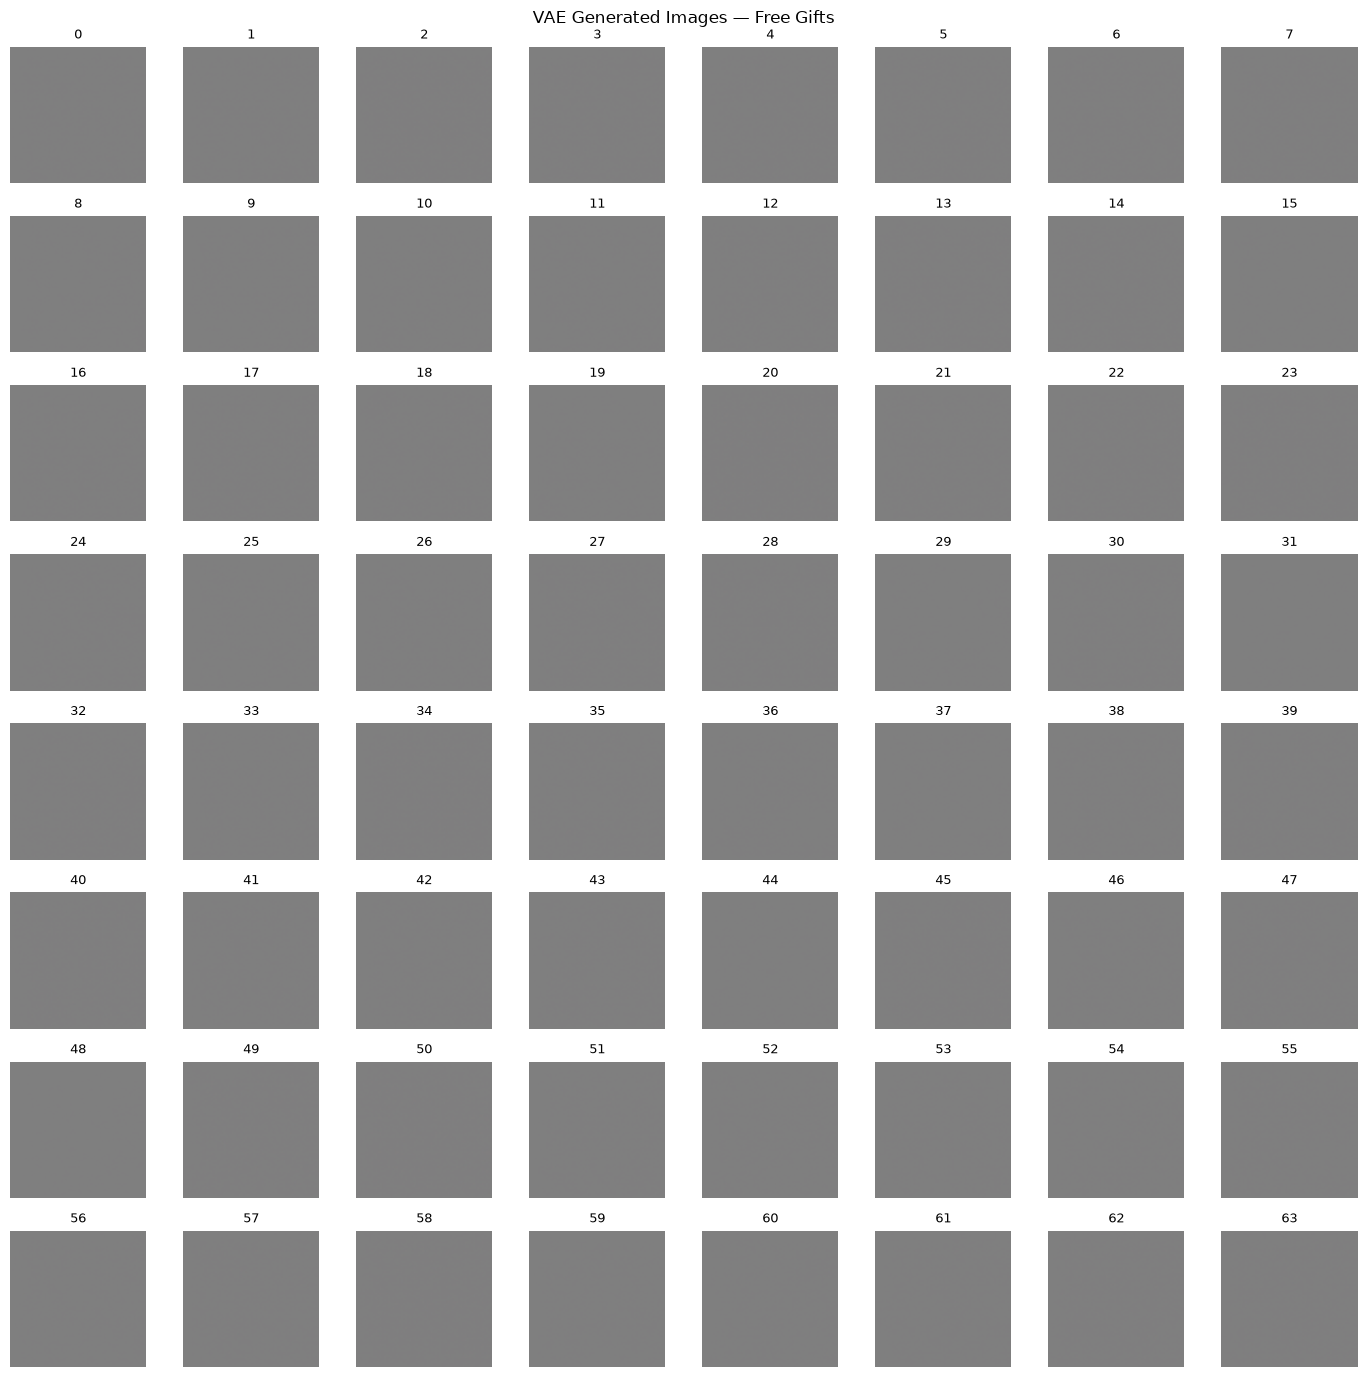

Mean pairwise difference: 0.00076431985
Near-duplicate pairs: 2016


In [21]:

N_CANDIDATES = 64

rng = np.random.default_rng(SEED + 1)

latent_vectors = rng.normal(
    size=(N_CANDIDATES, LATENT_DIM)
).astype("float32")

generated_images = decoder.predict(
    latent_vectors,
    verbose=0
)

fig, axes = plt.subplots(8, 8, figsize=(14, 14))

for i, ax in enumerate(axes.flat):
    image = np.clip(
        generated_images[i], 0, 1
    )

    ax.imshow(image)
    ax.set_title(f"{i}", fontsize=9)
    ax.axis("off")

plt.suptitle(
    f"VAE Generated Images — {target_class}"
)

plt.tight_layout()
plt.show()


# Basic image diversity check
distances = []

for i in range(N_CANDIDATES):
    for j in range(i + 1, N_CANDIDATES):
        difference = np.mean(
            np.abs(
                generated_images[i] - generated_images[j]
            )
        )

        distances.append(difference)

print("Mean pairwise difference:", np.mean(distances))
print(
    "Near-duplicate pairs:",
    sum(d < 0.015 for d in distances)
)


In [24]:

# Enter the indices of realistic images from Cell 9
APPROVED_INDICES = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

if not APPROVED_INDICES:
    raise ValueError(
        "Select realistic image indices from Cell 9 first."
    )

if len(APPROVED_INDICES) != len(set(APPROVED_INDICES)):
    raise ValueError("Duplicate indices are not allowed.")

if any(
    i < 0 or i >= N_CANDIDATES
    for i in APPROVED_INDICES
):
    raise ValueError("Invalid generated image index.")

# Never add more synthetic samples than real target-class
# training images in this first controlled experiment.
APPROVED_INDICES = APPROVED_INDICES[:len(target_paths)]

output_dir = SYNTH_DIR / target_class.replace(" ", "_")
output_dir.mkdir(parents=True, exist_ok=True)

synthetic_items = []

for idx in APPROVED_INDICES:
    image = np.clip(
        generated_images[idx], 0, 1
    )

    image_uint8 = (
        image * 255
    ).astype(np.uint8)

    output_path = output_dir / f"synthetic_{idx:03d}.png"

    encoded = tf.io.encode_png(image_uint8)

    tf.io.write_file(
        str(output_path),
        encoded
    )

    synthetic_items.append(
        (str(output_path), target_class)
    )

print("Selected synthetic images:", len(synthetic_items))
print("Saved in:", output_dir)


Selected synthetic images: 10
Saved in: C:\Users\Abhishek\Desktop\RetailMind-AI\data\synthetic\day11\Free_Gifts


In [25]:

augmented_items = train_items + synthetic_items

augmented_train_ds = make_dataset(
    augmented_items,
    training=True
)

print("Original training images:", len(train_items))
print("Synthetic images added:", len(synthetic_items))
print("New training total:", len(augmented_items))

# Reset seed to reproduce the baseline's initialization
keras.utils.set_random_seed(SEED)

augmented_model = build_catalog_cnn(
    input_shape=(CNN_IMAGE_SIZE, CNN_IMAGE_SIZE, 3),
    class_count=len(class_names)
)

augmented_history = augmented_model.fit(
    augmented_train_ds,
    validation_data=val_ds,
    epochs=CNN_EPOCHS,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ],
    verbose=1
)

augmented_model.save(
    MODELS_DIR / "day11_augmented_cnn.keras"
)

print("Augmented classifier saved.")


Original training images: 6812
Synthetic images added: 10
New training total: 6822
Epoch 1/5


c:\Users\Abhishek\Desktop\RetailMind-AI\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


214/214 ━━━━━━━━━━━━━━━━━━━━ 80s 363ms/step - accuracy: 0.0582 - loss: 3.2036 - val_accuracy: 0.1103 - val_loss: 2.9716
Epoch 2/5
214/214 ━━━━━━━━━━━━━━━━━━━━ 82s 380ms/step - accuracy: 0.1217 - loss: 2.8990 - val_accuracy: 0.1725 - val_loss: 2.7315
Epoch 3/5
214/214 ━━━━━━━━━━━━━━━━━━━━ 78s 362ms/step - accuracy: 0.1689 - loss: 2.7292 - val_accuracy: 0.2578 - val_loss: 2.5510
Epoch 4/5
214/214 ━━━━━━━━━━━━━━━━━━━━ 84s 390ms/step - accuracy: 0.2268 - loss: 2.5130 - val_accuracy: 0.2828 - val_loss: 2.3449
Epoch 5/5
214/214 ━━━━━━━━━━━━━━━━━━━━ 88s 409ms/step - accuracy: 0.2719 - loss: 2.3375 - val_accuracy: 0.3728 - val_loss: 2.1263
Augmented classifier saved.


OVERALL RESULTS
---------------------------------------------
Baseline accuracy:  0.3417
Augmented accuracy: 0.3701
Accuracy change:    +0.0284

Baseline macro recall:  0.2711
Augmented macro recall: 0.3024

PER-CLASS RECALL
-----------------------------------------------------------------
Category                    Before     After    Change
Accessories                  0.000     0.000    +0.000
Apparel Set                  0.000     0.000    +0.000
Bags                         0.037     0.237    +0.200
Belts                        0.725     0.900    +0.175
Bottomwear                   0.500     0.362    -0.138
Cufflinks                    0.000     0.000    +0.000
Dress                        0.250     0.000    -0.250
Eyewear                      0.875     0.900    +0.025
Flip Flops                   0.225     0.237    +0.012
Fragrance                    0.163     0.237    +0.075
Free Gifts                   0.000     0.000    +0.000
Headwear                     0.276     0.172    -

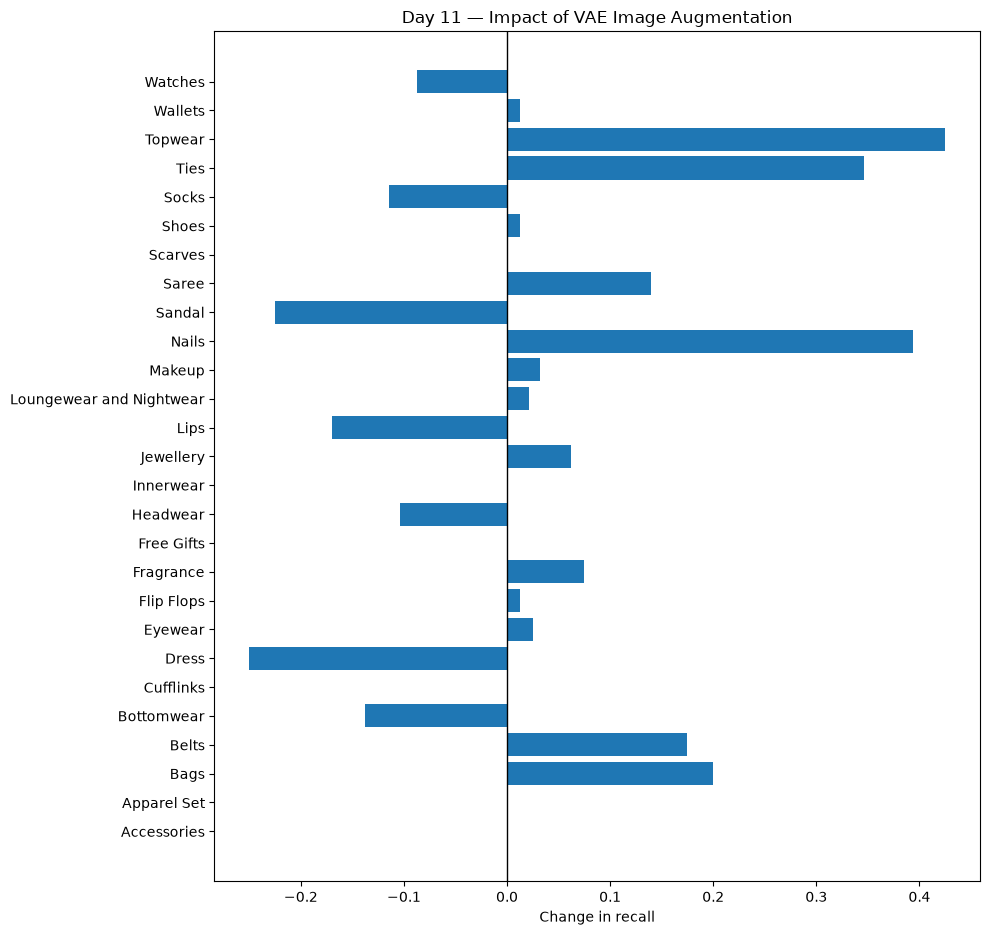


TARGET CATEGORY: Free Gifts
Before: 0.0
After: 0.0
Change: 0.0


In [26]:

test_true = np.array([
    label_to_id[label]
    for path, label in test_items
])


def evaluate_model(model):
    predictions = model.predict(
        test_ds,
        verbose=0
    ).argmax(axis=1)

    cm = tf.math.confusion_matrix(
        test_true,
        predictions,
        num_classes=len(class_names)
    ).numpy()

    support = cm.sum(axis=1)

    per_class_recall = (
        np.diag(cm) / np.maximum(support, 1)
    )

    accuracy = np.trace(cm) / cm.sum()
    macro_recall = np.mean(per_class_recall)

    return accuracy, macro_recall, per_class_recall, cm


base_acc, base_macro, base_recalls, base_cm = (
    evaluate_model(baseline_model)
)

aug_acc, aug_macro, aug_recalls, aug_cm = (
    evaluate_model(augmented_model)
)

print("OVERALL RESULTS")
print("-" * 45)

print(f"Baseline accuracy:  {base_acc:.4f}")
print(f"Augmented accuracy: {aug_acc:.4f}")
print(f"Accuracy change:    {aug_acc - base_acc:+.4f}")

print(f"\nBaseline macro recall:  {base_macro:.4f}")
print(f"Augmented macro recall: {aug_macro:.4f}")

print("\nPER-CLASS RECALL")
print("-" * 65)

print(
    f"{'Category':24s}"
    f"{'Before':>10s}"
    f"{'After':>10s}"
    f"{'Change':>10s}"
)

for i, name in enumerate(class_names):
    change = aug_recalls[i] - base_recalls[i]

    print(
        f"{name:24s}"
        f"{base_recalls[i]:10.3f}"
        f"{aug_recalls[i]:10.3f}"
        f"{change:+10.3f}"
    )

# Visualize improvement or degradation per category
changes = aug_recalls - base_recalls

plt.figure(
    figsize=(10, max(6, len(class_names) * 0.35))
)

plt.barh(class_names, changes)
plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Change in recall")
plt.title("Day 11 — Impact of VAE Image Augmentation")
plt.tight_layout()
plt.show()

target_idx = label_to_id[target_class]

print("\nTARGET CATEGORY:", target_class)
print("Before:", round(float(base_recalls[target_idx]), 4))
print("After:", round(float(aug_recalls[target_idx]), 4))
print(
    "Change:",
    round(
        float(aug_recalls[target_idx] - base_recalls[target_idx]),
        4
    )
)


In [27]:

results_path = DOCS_DIR / "day11_per_class_results.csv"

with open(results_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)

    writer.writerow([
        "category",
        "test_support",
        "baseline_recall",
        "augmented_recall",
        "recall_change"
    ])

    for i, name in enumerate(class_names):
        writer.writerow([
            name,
            int(base_cm[i].sum()),
            float(base_recalls[i]),
            float(aug_recalls[i]),
            float(aug_recalls[i] - base_recalls[i])
        ])


# Save confusion matrices
np.save(
    DOCS_DIR / "day11_baseline_confusion_matrix.npy",
    base_cm
)

np.save(
    DOCS_DIR / "day11_augmented_confusion_matrix.npy",
    aug_cm
)


target_idx = label_to_id[target_class]

report = f"""# RetailMind AI — Day 11

## VAE Image Augmentation

### Objective
Generate synthetic images for a minority product category
and measure their effect on image classification accuracy.

### Dataset
Fashion Product Images (Small), Kaggle

Dataset location: Local Keras cache
Classification labels: {LABEL_COLUMN}
Number of categories: {len(class_names)}

Real training images: {len(train_items)}
Validation images: {len(val_items)}
Test images: {len(test_items)}

Training samples per class capped at: {MAX_TRAIN_PER_CLASS}
Evaluation samples per class capped at: {MAX_EVAL_PER_CLASS}

### Minority Category Selection
Category: {target_class}
Original category images: {original_counts[target_class]}
Available training images: {train_counts[target_class]}
Reference confusion matrix: {reference_source}

### Generative Model
Model: Convolutional Variational Autoencoder
Framework: TensorFlow / Keras
VAE image resolution: {VAE_IMAGE_SIZE} x {VAE_IMAGE_SIZE}
Latent dimensions: {LATENT_DIM}
Epochs: {VAE_EPOCHS}

Generated candidates: {N_CANDIDATES}
Manually approved samples: {len(synthetic_items)}

### Classifier
Architecture: Original Day 6 Catalog CNN
Classifier resolution: {CNN_IMAGE_SIZE} x {CNN_IMAGE_SIZE}
Training epochs (maximum): {CNN_EPOCHS}

### Overall Results
Baseline accuracy: {base_acc:.4f}
Augmented accuracy: {aug_acc:.4f}
Accuracy change: {aug_acc - base_acc:+.4f}

Baseline macro recall: {base_macro:.4f}
Augmented macro recall: {aug_macro:.4f}

### Target Category Results
Category: {target_class}
Before augmentation recall: {base_recalls[target_idx]:.4f}
After augmentation recall: {aug_recalls[target_idx]:.4f}
Recall change: {aug_recalls[target_idx] - base_recalls[target_idx]:+.4f}

### Weekly Assessment 04
The full per-class comparison is saved in:
docs/day11_per_class_results.csv

### Limitations
- This is a controlled Day 11 CNN experiment, not a
  direct comparison of previously saved Day 6/7 scores.
- The training sample limit reduces resource requirements.
- Synthetic samples are selected through manual inspection.
- The generator uses 64x64 images, which are resized to
  128x128 for CNN training.
- Single-run changes may reflect training randomness.
- Per-class recall is not equivalent to demographic fairness.
- If the earlier confusion matrix was unavailable,
  selection used Day 11 validation predictions instead.

### Conclusion
Observed overall accuracy change: {aug_acc - base_acc:+.4f}
Observed target category recall change:
{aug_recalls[target_idx] - base_recalls[target_idx]:+.4f}

These measurements describe this experiment only.
"""


report_path = DOCS_DIR / "day11_generative_augmentation.md"

report_path.write_text(
    report,
    encoding="utf-8"
)

# Update README
readme_path = ROOT / "README.md"

readme_content = readme_path.read_text(
    encoding="utf-8"
) if readme_path.exists() else ""

heading = "## Day 11 — VAE Image Augmentation"

if heading not in readme_content:
    readme_entry = f"""

{heading}

- Built a convolutional VAE using TensorFlow/Keras.
- Selected minority category: {target_class}.
- Generated and reviewed synthetic product images.
- Added {len(synthetic_items)} synthetic training images.
- Retrained the Day 6 CNN for comparison.
- Baseline test accuracy: {base_acc:.4f}.
- Augmented test accuracy: {aug_acc:.4f}.
- Results: `docs/day11_generative_augmentation.md`.
- Per-class results: `docs/day11_per_class_results.csv`.
"""

    with open(readme_path, "a", encoding="utf-8") as f:
        f.write(readme_entry)

print("Day 11 experiment completed.")
print("Report:", report_path)
print("Results:", results_path)
print("README updated.")


Day 11 experiment completed.
Report: C:\Users\Abhishek\Desktop\RetailMind-AI\docs\day11_generative_augmentation.md
Results: C:\Users\Abhishek\Desktop\RetailMind-AI\docs\day11_per_class_results.csv
README updated.
